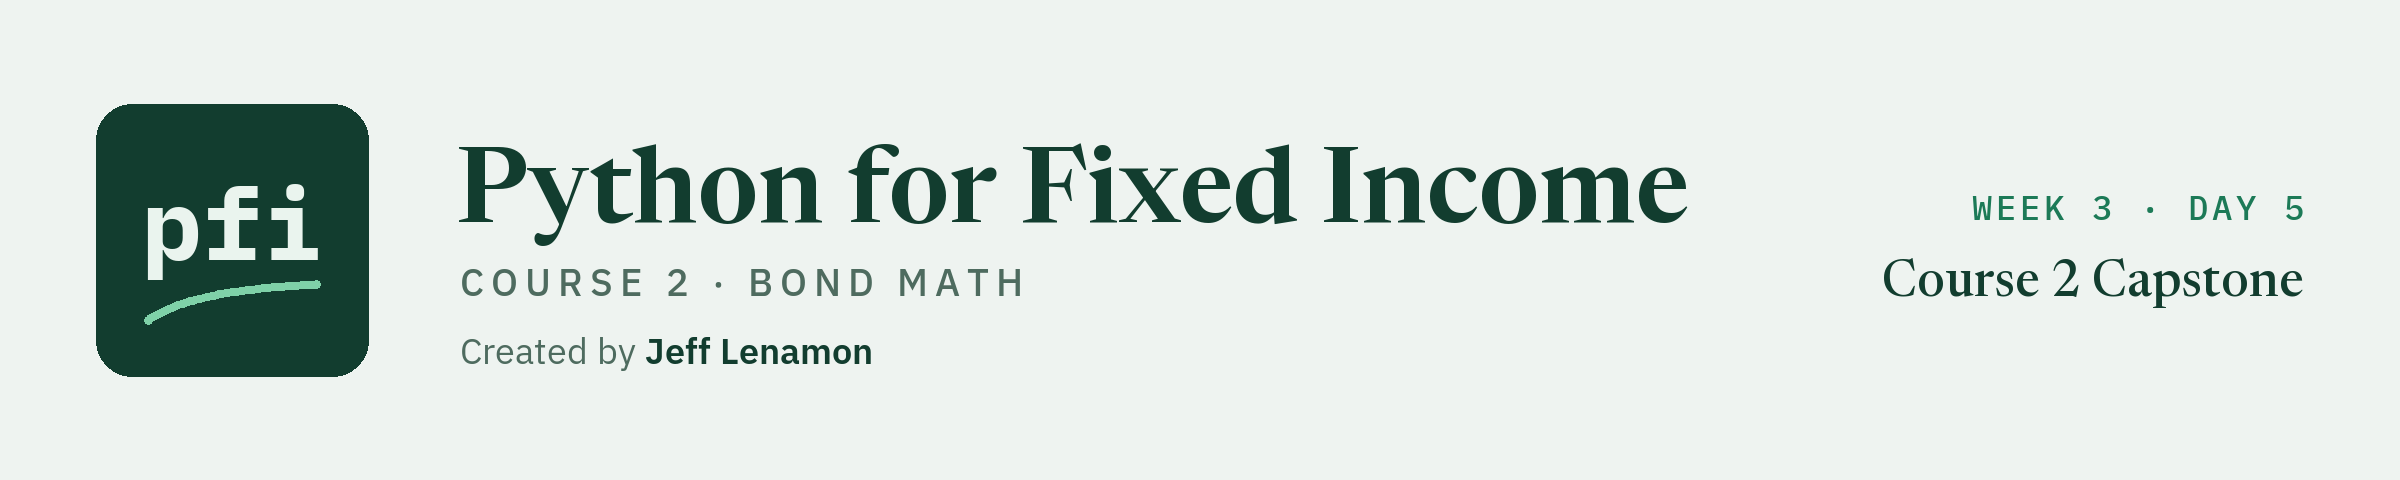

# Course 2 Capstone

Week 3, Day 5. November's extract proved with your own `bondmath`, cleaned by one function, reconciled, reported, rerun on September, and written up. You write the code.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day5/course2_capstone.ipynb)

## The Brief

### The Desk Lead's Note

The desk lead's fifteenth note:

> Month end. Operations sent November's extract with a cover note. Before any number leaves the desk, prove the file: every column repriced with your own `bondmath`, every difference explained, the fixes in one function so next month is one call. Then the risk report as a workbook: DV01, duration, spread and DTS by sector and rating, and the rate and spread what-ifs. Run the same functions on September and show me what changed. One page. Describe it: no views on any bond, issuer, or sector.

The file's problems are planted and unnamed, and every name is invented.

### The Cover Note

```
To: Credit desk
From: Operations
Subject: Month-end holdings extract, as of 2026-11-30

The month-end extract is attached as course2_capstone_holdings.csv. It is the same layout as last month.

Control totals for the book:
  Number of bonds:      199
  Total face:           493,000,000 dollars
  Total market value:   496,372,835.00 dollars

Market value is face times clean price plus accrued interest, divided by 100.
All positions settle and are priced as of 2026-11-30. Analytics are semiannual, 30/360.
Please tell us if the extract does not agree with these totals.
```

### The Capstone on One Page

![The capstone on one page: nine sections in three sittings. First sitting: 1 the file and its note, 2 test the inputs, 3 fix the inputs. Second sitting: 4 reprice every bond, ending at the checkpoint; 5 package it as clean_book, deliverable 2 and a commit; 6 the reconciliation, deliverable 3. Third sitting: 7 the risk report, deliverable 4 and a commit; 8 rerun on September, deliverable 5 and a commit; 9 the AI check, the log and the page, deliverables 7 and 8, a commit and the tag. Under all nine, bondmath.py as notebook 14 left it, 40 tests passing, deliverable 1. Deliverable 6 is the four commits and the tag](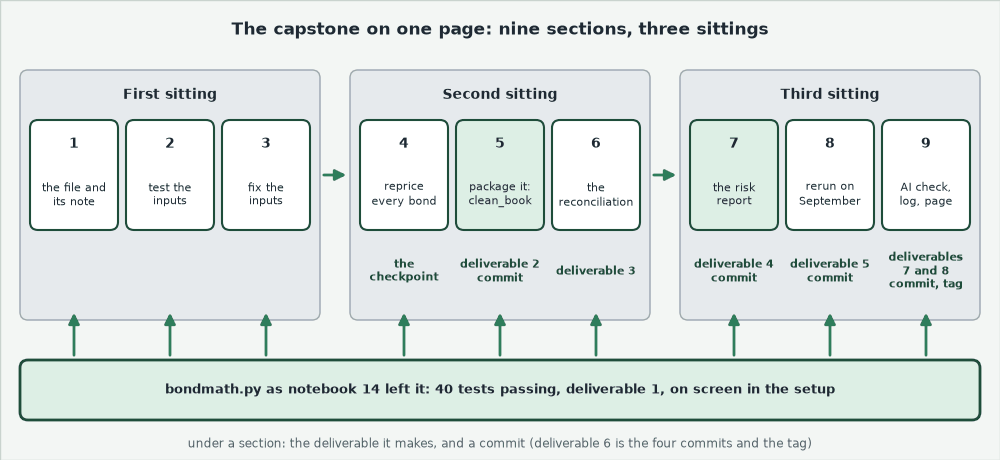)

**Nine sections, three sittings, one page at the end. Your module does the checking.**

### The Rules

1. **Work in a copy:** fixes go to `book`, never to `raw`.
2. **State every decision** in a markdown cell: what, how many rows, what evidence.
3. **Print `headline()` before and after every fix.**
4. **Every analytic comes from `bondmath`,** on the cover note's conventions.
5. **Describe:** never recommend, rank, or forecast; a scenario is a what-if.
6. **Every Git command names the work folder:** `!git -C "{work}" ...`.
7. **Restart and Run All** before you hand in.

An AI assistant is allowed: the docstring is the prompt, and every answer is tested and logged in 9.2.

### How It Is Checked

Each `check()` compares a fingerprint of your answer with a stored one; round as each question asks.
The checkpoint after section 4 must pass before section 5; a Stuck block holds the decision it expects: open it after your own.
Worked answers: `course2_capstone_solutions.ipynb`, once your page is written.

## The Data

Units: `coupon` and `yield_pct` in percent, `oas` in basis points, `duration` and `spread_duration` in years, `dts` in years times basis points, `price` and `accrued` per 100 of face, and `par_held`, `amount_outstanding`, and `market_value` in dollars.

<table align="left">
<tr><th align="left">File</th><th align="left">What it is</th></tr>
<tr><td align="left"><code>course2_capstone_holdings.csv</code></td><td align="left">November's extract, in the 19 columns Course 1's project pictured</td></tr>
<tr><td align="left"><code>course2_capstone_cover_note.txt</code></td><td align="left">the cover note above</td></tr>
<tr><td align="left"><code>benchmark.csv</code></td><td align="left">821 bonds as of 2026-09-30</td></tr>
<tr><td align="left"><code>course2_treasury_curve.csv</code></td><td align="left">the desk's curve file (notebook 11)</td></tr>
<tr><td align="left"><code>ratings.csv</code></td><td align="left">the rating scale</td></tr>
<tr><td align="left"><code>holdings.csv</code></td><td align="left">September's book, clean (notebooks 06 to 14)</td></tr>
</table>
<br clear="left">

`oas` is the spread to notebook 12's formula curve, and `dts` is `spread_duration` times `oas`, to 1 decimal.

## Setup

Run these cells first and do not change them.

### Today's Work Folder

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 14 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(15)

Work folder pfi_course2_15_k4w7q2xr: 8 data files, the module as notebook 14 left it, 14 commits, tagged week1 and week2


### Deliverable 1: The Module's Tests

Your own `my_bondmath` may stand in: copy its two files in, your eight characters in place of `k4w7q2xr`, then rerun the next cell.

```powershell
Copy-Item "$HOME\projects\my_bondmath\bondmath.py", "$HOME\projects\my_bondmath\test_bondmath.py" "$env:TEMP\pfi_course2_15_k4w7q2xr"
```

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 0.50s



**Deliverable 1 is on screen: 40 tests pass.**

### Imports and the Files

In [3]:
import importlib
import math
import re
from datetime import date

import bondmath
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

# the files start_day copied into the work folder; raw is the extract exactly as it arrived
raw = pd.read_csv('course2_capstone_holdings.csv')
benchmark = pd.read_csv('benchmark.csv')
ratings = pd.read_csv('ratings.csv')
curve = pd.read_csv('course2_treasury_curve.csv')
september = pd.read_csv('holdings.csv')
# the cover note's control totals
expected_bonds = 199
expected_face = 493_000_000
expected_value = 496_372_835.00


def headline(label, table):
    # the headline numbers, printed before and after every fix, as in Course 1's EDA notebook
    print(f"{label}: {len(table):,} rows | face {table['par_held'].sum():,} | "
          f"market value {table['market_value'].sum():,.2f} | "
          f"mean yield {table['yield_pct'].mean():.3f}")


print('benchmark', benchmark.shape, '| ratings', ratings.shape, '| curve', curve.shape,
      '| september', september.shape)

benchmark (821, 19) | ratings (18, 4) | curve (10, 2) | september (200, 19)


### `check()`

In [4]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written here
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    # a number is rounded to the places the question asks for, so 7 and 7.0 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + '|' + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have ' + str(answer))

## 1 The File and Its Note

### 1.1 Rows, Columns, and a Working Copy

Q. What shape is the extract (**answer_1_1**)? Copy `raw` to `book`: every fix from here goes to `book`.

**Write down the row count: the cover note says 199.**

In [5]:
# your code here
book = ...
answer_1_1 = ...

check('Question 1.1', answer_1_1, '27e687cbc05d')

Question 1.1: not attempted yet


### 1.2 The File Less Its Note

Q. Print `headline()` as received, then the file less the note in rows, face (**answer_1_2**), and market value. What do the gaps suggest?

**The totals test a file first; section 2 finds what moves them.**

In [6]:
# your code here
answer_1_2 = ...

check('Question 1.2', answer_1_2, '6a6b09d5d958', places=0)

Question 1.2: not attempted yet


## 2 Test the Inputs

The note's totals count dollars; seven rules test the rest.
Count on `book` as 1.1 made it, and fix nothing until section 3.

<table align="left">
<tr><th align="left">Rule</th><th align="left">What the desk expects</th></tr>
<tr><td align="left">1</td><td align="left">one row for each bond, no row a copy</td></tr>
<tr><td align="left">2</td><td align="left">the maturity after the as-of date</td></tr>
<tr><td align="left">3</td><td align="left">no number missing</td></tr>
<tr><td align="left">4</td><td align="left">coupon and yield in percent, price and accrued per 100 of face</td></tr>
<tr><td align="left">5</td><td align="left">market value is face x (price + accrued) / 100, to the cent</td></tr>
<tr><td align="left">6</td><td align="left">every analytic reproduces from the bond's terms with <code>bondmath</code> (section 4)</td></tr>
<tr><td align="left">7</td><td align="left">CUSIPs, ratings, sizes, spread durations, and price dates well formed</td></tr>
</table>
<br clear="left">

Tools: Course 1's `duplicated()`, `isna()`, `describe()`, `.str.fullmatch()`, `isin()`.
Text dates written year-month-day sort in date order, so `<=` compares them.

**Every rule gets a count: failures are the fix list, passes go in the page.**

### 2.1 Rule 1: One Row for Each Bond

Q. How many rows copy an earlier row exactly (**answer_2_1**)? Show each beside its original, with the face and value they carry.

<details><summary>Stuck? The expected decision</summary>

Remove exact copies, keeping the first of each, and renumber the rows.

</details>

In [7]:
# your code here
answer_2_1 = ...

check('Question 2.1', answer_2_1, 'aadc199a297c', places=0)

Question 2.1: not attempted yet


### 2.2 Rule 2: The Maturity

Q. How many rows mature on or before the as-of date (**answer_2_2**)? Show them with coupon, maturity, and duration: which column is wrong?

<details><summary>Stuck? The expected decision</summary>

The benchmark's maturity for the same CUSIP, once the two files agree on its ticker.

</details>

In [8]:
# your code here
answer_2_2 = ...

check('Question 2.2', answer_2_2, '638d0c69ab0f', places=0)

Question 2.2: not attempted yet


### 2.3 Rule 3: Missing Numbers

Q. How many cells are missing (**answer_2_3**)? Which of each row's other numbers gives the blank back through your module?

<details><summary>Stuck? The expected decision</summary>

Drop no row: a blank yield is `yield_to_maturity` from the price, a blank price `price` from the yield, to 3 decimals.

</details>

In [9]:
# your code here
answer_2_3 = ...

check('Question 2.3', answer_2_3, '99bce1a159e6', places=0)

Question 2.3: not attempted yet


### 2.4 Rule 4: Units

Q. Summarize `coupon` and `yield_pct`. How many coupons (**answer_2_4a**) and yields (**answer_2_4b**) are below 1 percent? Show those rows with price and accrued.

<details><summary>Stuck? The expected decision</summary>

A coupon or yield below 1 was entered as a decimal: times 100, to 3 decimals.

</details>

In [10]:
# your code here
answer_2_4a = ...
answer_2_4b = ...

check('Question 2.4 coupons', answer_2_4a, '08c62009b4d4', places=0)
check('Question 2.4 yields', answer_2_4b, '9a54f14f80a8', places=0)

Question 2.4 coupons: not attempted yet
Question 2.4 yields: not attempted yet


### 2.5 Rules 5 and 7

Q. How many rows miss rule 5 by more than half a cent (**answer_2_5a**), and how many could be tested? Total the breaks of rule 7 (**answer_2_5b**).

In [11]:
# your code here
answer_2_5a = ...
answer_2_5b = ...

check('Question 2.5 tie-out', answer_2_5a, '51b7fe7570fc', places=0)
check('Question 2.5 rule 7', answer_2_5b, 'd8983dbd80c1', places=0)

Question 2.5 tie-out: not attempted yet
Question 2.5 rule 7: not attempted yet


## 3 Fix the Inputs

![Inputs first: section 4 reprices every bond from settlement, maturity, coupon, and yield, and stands on four inputs. Copies: one row per bond, or a bond counts twice. Maturity: after the as-of date, since coupon_dates stops on a past one. Units: coupon and yield in percent, since 0.05 prices nonsense. Blanks: a price and a yield in every row, since a blank cannot be priced](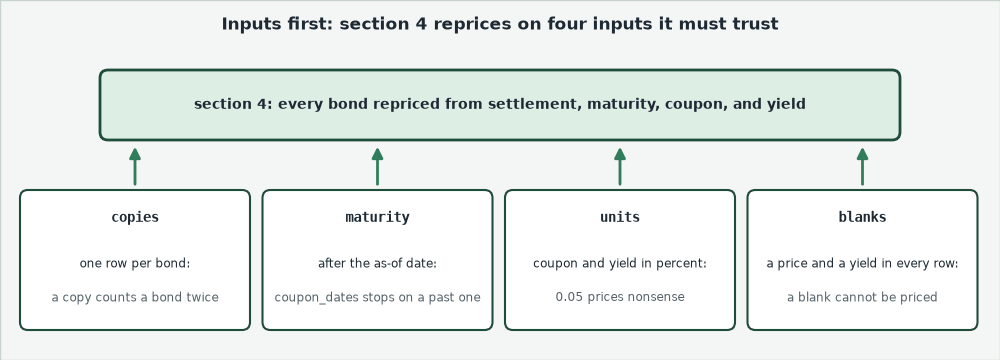)

Each fix gets a decision cell, then `headline()` before and after it.

Tools: Course 1's `drop_duplicates()`, `.loc[mask, column] =`; `date.fromisoformat` (notebook 06).

### 3.1 Copies, Maturity, and Units

Q. Make your three fixes. Give the face after them (**answer_3_1a**), the corrected maturity as text year-month-day (**answer_3_1b**), and the mean coupon to 3 places (**answer_3_1c**).

In [12]:
# your code here: a decision cell and a fix cell for each fix
answer_3_1a = ...
answer_3_1b = ...
answer_3_1c = ...

check('Question 3.1 face', answer_3_1a, 'fd62f80a9c8b', places=0)
check('Question 3.1 maturity', answer_3_1b, '2755386de0d9')
check('Question 3.1 mean coupon', answer_3_1c, '59506b3d5415', places=3)

Question 3.1 face: not attempted yet
Question 3.1 maturity: not attempted yet
Question 3.1 mean coupon: not attempted yet


### 3.2 Fill the Blanks

Q. Fill each blank from the other number of its pair. Give the sum of the yields you filled (**answer_3_2a**) and of the prices (**answer_3_2b**), each to 3 places.

**Totals that tie cannot see a wrong price; section 4 can. The first sitting ends here.**

In [13]:
# your code here
answer_3_2a = ...
answer_3_2b = ...

check('Question 3.2 yields', answer_3_2a, 'c0e61eb6bd31', places=3)
check('Question 3.2 prices', answer_3_2b, '8db14052fa4d', places=3)

Question 3.2 yields: not attempted yet
Question 3.2 prices: not attempted yet


## 4 Reprice Every Bond

![Rule 6 on row 0, 99049XAE2 BEZH: settlement 2026-11-30, maturity 2029-04-17, coupon 8.125, yield 9.073. From these four terms, accrued_interest gives accrued, price gives price, yield_to_maturity from the price gives yield_pct, modified_duration gives duration, spread_to_curve_bp with the curve gives oas, spread_duration gives spread_duration, and dts from the two above gives dts. Tolerances: 0.0005 for the columns rounded to 3 decimals, 0.001 percent for the yield, 1e-9 bp for oas, 0.05 for dts](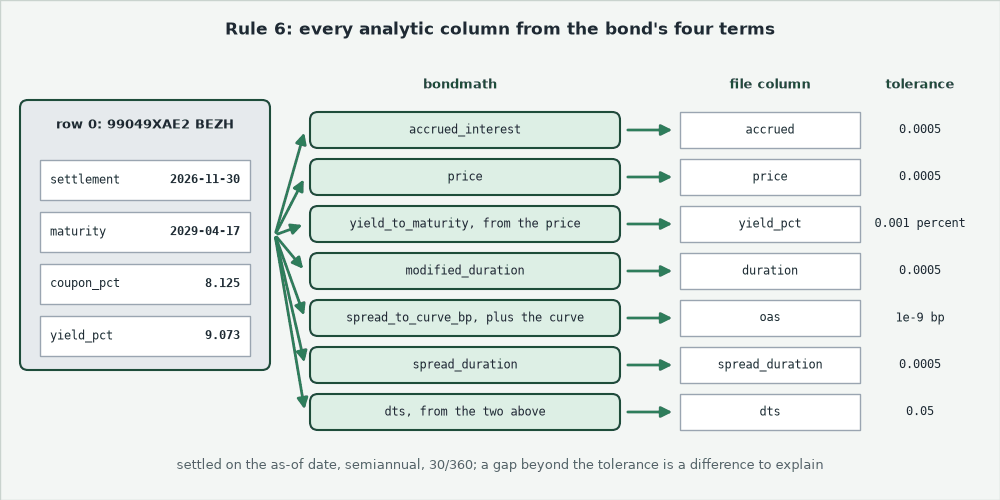)

The second sitting: recompute each column into a `_calc` column, count the rows beyond notebook 10's tolerance, then decide and fix.

Tools: `ROUNDED_3` (notebook 10), `*bond` (notebook 08), `.dt.is_month_end` (notebook 06).

### 4.1 Accrued Interest

Q. Add `accrued_calc`. How many rows of `accrued` are beyond tolerance (**answer_4_1**)? Set each beside coupon x actual days since the last coupon / 360. Decide and fix.

<details><summary>Stuck? The expected decision</summary>

Accrued equal to coupon x actual days / 360 was counted on the wrong day count: use `accrued_interest` on 30/360, to 3 decimals.

</details>

In [14]:
# your code here
answer_4_1 = ...

check('Question 4.1', answer_4_1, '2d66e80f087e', places=0)

Question 4.1: not attempted yet


### 4.2 Price and Yield

Q. Add `price_calc`. How many prices are beyond tolerance (**answer_4_2a**)? Compare each with `price_calc` plus accrued; decide and fix. Then give the largest gap of `yield_calc`, from the price, to `yield_pct`, to 4 places (**answer_4_2b**).

<details><summary>Stuck? The expected decision</summary>

A price equal to `price_calc` plus accrued is the dirty price: use price less accrued, to 3 decimals.

</details>

In [15]:
# your code here
answer_4_2a = ...
answer_4_2b = ...

check('Question 4.2 prices', answer_4_2a, 'fb3188e7852d', places=0)
check('Question 4.2 yield gap', answer_4_2b, 'f965708cf248', places=4)

Question 4.2 prices: not attempted yet
Question 4.2 yield gap: not attempted yet


### 4.3 Duration

Q. Add `duration_calc`. How many durations are beyond tolerance (**answer_4_3**)? Set each beside `spread_duration` and `macaulay_duration`. Decide and fix.

<details><summary>Stuck? The expected decision</summary>

A duration equal to Macaulay duration is the wrong duration: use `modified_duration`, to 3 decimals.

</details>

In [16]:
# your code here
answer_4_3 = ...

check('Question 4.3', answer_4_3, 'b3e709fd267c', places=0)

Question 4.3: not attempted yet


### 4.4 The Two Special Bonds

One bond matures on a month end (notebook 06's rule); one has a single coupon left (notebook 08).

Q. Print the month-end bond's `coupon_dates`, 30/360 days accrued, and accrued, and give its next coupon date as text (**answer_4_4a**). Print the final-period bond's A, E, and DSC, and give its dirty price to 6 places (**answer_4_4b**).

**Excel side by side.** Tested in desktop Excel for Windows.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Month-end bond, next coupon</td><td align="left"><code>coupon_dates(...)[1]</code></td><td align="left"><code>=COUPNCD(DATE(2026,11,30),DATE(2033,8,31),2,0)</code></td></tr>
<tr><td align="left">Its clean price</td><td align="left"><code>price(*bond)</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2033,8,31),5.5/100,5.7/100,100,2,0)</code></td></tr>
<tr><td align="left">Final-period bond, clean price</td><td align="left"><code>price(*bond)</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2027,3,15),4.25/100,4.193/100,100,2,0)</code></td></tr>
</table>
<br clear="left">

In [17]:
# your code here
answer_4_4a = ...
answer_4_4b = ...

check('Question 4.4 next coupon', answer_4_4a, 'bbed8c195fae')
check('Question 4.4 dirty price', answer_4_4b, 'c0c321eb15fc', places=6)

Question 4.4 next coupon: not attempted yet
Question 4.4 dirty price: not attempted yet


### 4.5 Dirty Price, DV01, and Convexity

Q. Add `dirty_price`, `dv01`, and `convexity`, and check each DV01 against notebook 09's bump, leaving out the final-period bond. Give the book's DV01 in dollars, to 2 places (**answer_4_5**).

In [18]:
# your code here
answer_4_5 = ...

check('Question 4.5', answer_4_5, 'f67acd7aeac5', places=2)

Question 4.5: not attempted yet


### 4.6 Spread to the Curve, Two Ways

Q. Add `spread_bp` on notebook 12's formula curve, and `spread_bp_table` on `curve`. How many `spread_bp` are more than 1e-9 bp from `oas` (**answer_4_6a**)? Give the largest gap of `spread_bp_table` to `oas`, to 2 places (**answer_4_6b**).

In [19]:
# your code here
answer_4_6a = ...
answer_4_6b = ...

check('Question 4.6 formula curve', answer_4_6a, 'c1de86bf3f73', places=0)
check('Question 4.6 curve file', answer_4_6b, '743ff3bfa57c', places=2)

Question 4.6 formula curve: not attempted yet
Question 4.6 curve file: not attempted yet


### 4.7 Spread Duration and DTS

Q. Add `spread_duration_calc`, and `dts_calc` from it and `spread_bp`. How many `spread_duration` (**answer_4_7a**) and `dts` (**answer_4_7b**, tolerance 0.05 + 1e-9) are beyond tolerance? Recompute DTS from the file's own `spread_duration`: what explains them?

<details><summary>Stuck? The expected decision</summary>

Keep both as delivered: DTS that reproduces from the file's own spread duration is rounding (notebook 13), and the final-period bond's spread duration is a convention.

</details>

In [20]:
# your code here
answer_4_7a = ...
answer_4_7b = ...

check('Question 4.7 spread duration', answer_4_7a, '22c9e4900f9e', places=0)
check('Question 4.7 DTS', answer_4_7b, '480f2a44687f', places=0)

Question 4.7 spread duration: not attempted yet
Question 4.7 DTS: not attempted yet


### Checkpoint: The Repriced Book

Q. Does `book` match the cover note and the expected decisions? Every line must read `correct` before section 5.

In [21]:
# the repriced book against the cover note and the decisions the worked version made
if book is ...:
    print('Checkpoint: not attempted yet')
else:
    check('Checkpoint rows', len(book), '3d983147e286', places=0)
    check('Checkpoint face', book['par_held'].sum(), '9e70885ed664', places=0)
    check('Checkpoint market value', book['market_value'].sum(), 'b6ff2e33a3ad', places=2)
    check('Checkpoint blank cells', book[raw.columns].isna().sum().sum(), '06dcfb197545', places=0)
    check('Checkpoint mean price', book['price'].mean(), '3d069320c85f', places=3)
    check('Checkpoint mean accrued', book['accrued'].mean(), 'aac97353a765', places=3)
    check('Checkpoint mean yield', book['yield_pct'].mean(), '9eabc5126ad2', places=3)
    check('Checkpoint mean duration', book['duration'].mean(), '77c57b445f1e', places=3)
    check('Checkpoint raw is unchanged', raw.shape, 'e2d7cc3fb2b9')

Checkpoint: not attempted yet


## 5 Package It

**Every column reprices, or has a reason it does not: now one call does it all.**

### 5.1 `clean_book`, Docstring First

Q. In `capstone.py`, written with `%%writefile` in a cell of its own, write `clean_book(raw, benchmark, curve)`: a docstring listing your seven decisions, then the decisions and section 4's columns, its inputs unchanged. `assert` each rule it promises, with a message. Store its result on `raw` in **cleaned**, `assert` the control totals, and show `cleaned` equals `book`.

In [22]:
# your code here
cleaned = ...

if cleaned is ...:
    print('Question 5.1: not attempted yet')
else:
    check('Question 5.1 rows', len(cleaned), '388d9cdf66b9', places=0)
    check('Question 5.1 face', cleaned['par_held'].sum(), '501b1706b7a6', places=0)
    check('Question 5.1 market value', cleaned['market_value'].sum(), 'e3b9db7ccd1a', places=2)
    check('Question 5.1 blank cells', cleaned.isna().sum().sum(), 'a29bc14944c4', places=0)
    check('Question 5.1 same as book', cleaned[raw.columns].equals(book[raw.columns]),
          'f4ae2129e720')
    check('Question 5.1 raw is unchanged', raw.shape, 'ce69d610978f')

Question 5.1: not attempted yet


### 5.2 Commit It

Q. Commit `capstone.py` alone, with a subject naming the deliverable, and show the history.

**One call rebuilds the book from the file as it arrived.**

In [23]:
# your Git commands here, each written !git -C "{work}" ...

## 6 The Reconciliation

![Three reasons, then none. A cell beyond tolerance is asked three questions in order, and takes the first reason that fits. Changed by a clean_book decision: a decision of clean_book. The bond is in its final coupon period: final coupon period. DTS reproduces from the file's own spread_duration: rounding in the file. A cell that fits none is unexplained, a dashed box, and the reconciliation's goal is that nothing reaches it](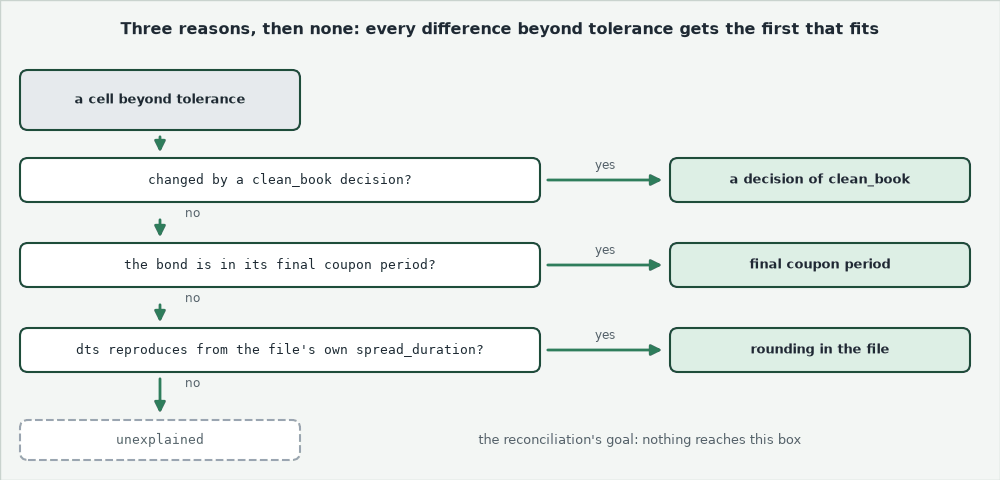)

A **reconciliation** sets the file's numbers beside your module's and gives every difference a reason.

### 6.1 Delivered Against Recomputed

Q. Line up the extract, without its copies, row for row with `cleaned`. Count the cells beyond tolerance (**answer_6_1**): `coupon` and `maturity` against the cleaned values, and the eight other analytic and value columns against what `bondmath` recomputed. A blank is a difference.

In [24]:
# your code here
answer_6_1 = ...

check('Question 6.1', answer_6_1, 'c097ff79ca22', places=0)

Question 6.1: not attempted yet


### 6.2 A Reason for Every Difference

Q. Build **reconciliation**, one row per difference: CUSIP, column, delivered, recomputed, and the first reason in the picture's order. How many are unexplained (**answer_6_2a**), and how many bonds did a decision change (**answer_6_2b**)?

In [25]:
# your code here
reconciliation = ...
answer_6_2a = ...
answer_6_2b = ...

check('Question 6.2 unexplained', answer_6_2a, '127b5cf28a78', places=0)
check('Question 6.2 bonds changed', answer_6_2b, 'ce7041bcb2e0', places=0)

Question 6.2 unexplained: not attempted yet
Question 6.2 bonds changed: not attempted yet


### Every Difference by Its Reason

Q. Which column holds the most differences, and for what reason? This cell is written for you.

**Every difference has a name. The second sitting ends here.**

In [26]:
# written for you: each column's differences, split by reason (Course 1's Trade Blotter crosstab)
if reconciliation is ...:
    print('Chart: not attempted yet')
else:
    by_reason = pd.crosstab(reconciliation['column'], reconciliation['reason'])
    fig, ax = plt.subplots(figsize=(8, 4))
    by_reason.plot.barh(stacked=True, ax=ax)
    ax.set_title('Every Difference Has a Reason')
    ax.set_xlabel('Cells beyond tolerance')
    ax.set_ylabel('Column of the file')
    ax.legend(title='Reason')
    plt.show()

Chart: not attempted yet


## 7 The Risk Report

The third sitting, on notebook 14's risk card and full reprice.

### 7.1 `risk_report`

Q. Append `risk_report(book, ratings)` to `capstone.py` with `%%writefile -a`. It returns a dict of three tables:

* `positions`: one row per bond, adding bucket, grade, `weight_pct`, `dv01_dollars`, and `dts_contribution`;
* `summary`: the book, each sector, and each bucket in credit order: bonds, value, weight, DV01 in dollars, and value-weighted duration, spread, and DTS;
* `scenarios`: rates -100, -25, +25, +100 bp, spreads +10 percent and +25 bp, repriced in full and estimated, in dollars.

`positions` columns, in order: `cusip`, `ticker`, `issuer`, `sector`, `rating`, `bucket`, `grade`, `coupon`, `maturity`, `par_held`, `price`, `accrued`, `yield_pct`, `market_value`, `weight_pct`, `duration_calc`, `dv01`, `dv01_dollars`, `convexity`, `spread_bp`, `spread_duration_calc`, `dts_calc`, `dts_contribution`.

Store its result in **report**, and the book's duration to 3 places (**answer_7_1**).

In [27]:
# your code here
report = ...
answer_7_1 = ...

check('Question 7.1', answer_7_1, 'e018a375dff5', places=3)

Question 7.1: not attempted yet


### 7.2 By Sector and Rating

Q. Which sector carries the largest share of the book's DTS (**answer_7_2a**)? What percent of the DTS is High Yield, to 2 places (**answer_7_2b**)? Set each beside its share of value.

In [28]:
# your code here
answer_7_2a = ...
answer_7_2b = ...

check('Question 7.2 sector', answer_7_2a, '265dd381315b')
check('Question 7.2 High Yield', answer_7_2b, '8081778f49af', places=2)

Question 7.2 sector: not attempted yet
Question 7.2 High Yield: not attempted yet


### 7.3 The What-Ifs

Q. Give the +100 bp full reprice in dollars (**answer_7_3a**), and the -100 bp estimate less full reprice (**answer_7_3b**), both to 2 places. Why do the two part for a large move? Each is a mechanical what-if, never a forecast.

In [29]:
# your code here
answer_7_3a = ...
answer_7_3b = ...

check('Question 7.3 up 100', answer_7_3a, 'fe48762b453d', places=2)
check('Question 7.3 estimate gap', answer_7_3b, '788a5e108373', places=2)

Question 7.3 up 100: not attempted yet
Question 7.3 estimate gap: not attempted yet


### 7.4 The Workbook

Q. Write `course2_risk_report.xlsx`, a sheet per table, no row labels. Read it back and `assert` the positions sheet adds to the book's DV01 and the note's value. Give the sheet names as a list (**answer_7_4a**) and the positions rows (**answer_7_4b**).

**Excel side by side.** On `positions`, N is `market_value`, P `duration_calc`, R `dv01_dollars`, V `dts_calc`; tested in desktop Excel for Windows.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Book DV01 in dollars</td><td align="left"><code>positions['dv01_dollars'].sum()</code></td><td align="left"><code>=SUM(R2:R200)</code></td></tr>
<tr><td align="left">Book duration</td><td align="left"><code>bondmath.weighted_average(...)</code></td><td align="left"><code>=SUMPRODUCT(N2:N200,P2:P200)/SUM(N2:N200)</code></td></tr>
<tr><td align="left">Book DTS</td><td align="left"><code>bondmath.weighted_average(...)</code></td><td align="left"><code>=SUMPRODUCT(N2:N200,V2:V200)/SUM(N2:N200)</code></td></tr>
</table>
<br clear="left">

In [30]:
# your code here
answer_7_4a = ...
answer_7_4b = ...

check('Question 7.4 sheets', answer_7_4a, 'd2c365e514fc')
check('Question 7.4 positions rows', answer_7_4b, 'a5a733724748', places=0)

Question 7.4 sheets: not attempted yet
Question 7.4 positions rows: not attempted yet


### 7.5 Commit the Code, Not the Workbook

Q. Read `git status --short` and `git diff --stat`, then commit `capstone.py` alone, leaving the workbook untracked (notebook 14).

**The desk gets the workbook; the record gets the code that makes it.**

In [31]:
# your Git commands here, each written !git -C "{work}" ...

## 8 Rerun, Do Not Redo

### 8.1 September Through Both Functions

Q. Run `clean_book`, then `risk_report`, on `september`, unchanged. Do its delivered columns come back untouched? Give September's book DV01 in dollars, to 2 places (**answer_8_1**).

In [32]:
# your code here
answer_8_1 = ...

check('Question 8.1', answer_8_1, '47a4c88c7496', places=2)

Question 8.1: not attempted yet


### 8.2 A Test for Each Promise

Q. Write `test_capstone.py` with `test_clean_book_ties_to_the_cover_note` (November's three totals) and `test_clean_book_leaves_september_alone`. Run pytest below, give the count passed (**answer_8_2**), and commit the test file.

In [33]:
# your code here: start this cell with %%writefile test_capstone.py

In [34]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................................                                 [100%]
40 passed in 0.50s



In [35]:
# your code here
answer_8_2 = ...

check('Question 8.2', answer_8_2, '33b7a3db9e2f', places=0)

Question 8.2: not attempted yet


### 8.3 Two Months Side by Side

Q. Build **comparison**, columns `September`, `November`, and `change`, with a row each for bonds, market value, DV01, duration, spread, and DTS. Give the DTS change, November less September, to 1 place (**answer_8_3**).

In [36]:
# your code here
comparison = ...
answer_8_3 = ...

check('Question 8.3', answer_8_3, 'a7688f7ee362', places=1)

Question 8.3: not attempted yet


### The Change in Percent

Q. Which figures moved most from September? This cell is written for you.

**Two months, one call each, and a test that says so.**

In [37]:
# written for you: each figure's change in percent of September, signed, as in notebook 14
if comparison is ...:
    print('Chart: not attempted yet')
else:
    change_pct = (comparison['November'] / comparison['September'] - 1) * 100
    fig, ax = plt.subplots(figsize=(8, 3.5))
    bars = ax.barh(change_pct.index, change_pct)
    ax.axvline(0, color='#1E4D3A', linewidth=1)
    ax.bar_label(bars, fmt='{:+.1f}', padding=3)
    # room on both sides for the labels
    ax.set_xlim(change_pct.min() - 1.5, change_pct.max() + 1.5)
    ax.set_title('November Against September, Same Two Functions')
    ax.set_xlabel('Change, percent of September')
    plt.show()

Chart: not attempted yet


## 9 The Deliverables

### 9.1 The AI Check

You asked an assistant for one step of `clean_book`, with the docstring as the prompt.
This came back, written for this course in the style of an assistant's answer: it runs, and it breaks one convention.

In [38]:
def recompute_accrued(book):
    """Accrued interest per 100 of face for every bond in a month-end book.

    book has as_of_date and maturity (text, year-month-day) and coupon (percent a year).
    Settlement is each row's as_of_date. Convention: the book's own, as the cover note states:
    semiannual coupons on US 30/360. Returns a pandas Series of floats in the book's order.
    """
    settlements = [date.fromisoformat(text) for text in book['as_of_date']]
    maturities = [date.fromisoformat(text) for text in book['maturity']]
    # count the actual days in the period, the most precise day count
    accrued = [bondmath.accrued_interest(s, m, c, 2, 'ACT/ACT')
               for s, m, c in zip(settlements, maturities, book['coupon'])]
    return pd.Series(accrued, index=book.index)

Q. What should it return for the month-end bond? Your 4.4 printed it. Write down a number.

In [39]:
# the month-end bond's three terms, typed in
month_end_bond = pd.DataFrame({'as_of_date': ['2026-11-30'], 'maturity': ['2033-08-31'],
                               'coupon': [5.5]})
recompute_accrued(month_end_bond)

0    1.382597
dtype: float64

Q. Test it against Excel's accrued on the reference file's 200 holdings rows before you trust it.

In [40]:
# Excel's accrued for the holdings rows of the reference file, settled 2026-09-30 on 30/360
reference = pd.read_csv('bondmath_excel_reference.csv')
excel_rows = reference[reference['group'] == 'holdings']
test_book = pd.DataFrame({'as_of_date': excel_rows['settlement'],
                          'maturity': excel_rows['maturity'], 'coupon': excel_rows['coupon_pct']})
gap = (recompute_accrued(test_book) - excel_rows['accrued']).abs()
assert gap.max() < 1e-9, (f"{(gap >= 1e-9).sum()} rows differ from Excel's accrued; "
                          f"the largest gap is {gap.max():.6f}")
print(f"All {len(gap)} rows match Excel's accrued within 1e-9")

AssertionError: 200 rows differ from Excel's accrued; the largest gap is 0.015399

Q. Find the convention it broke, fix the function, and rerun until the test passes. On `cleaned`, give your function's accrued for the month-end bond, to 6 places (**ai_month_end**), and the bonds the assistant's version gets wrong by more than 1e-9 (**ai_rows_changed**).

In [41]:
# your code here
ai_month_end = ...
ai_rows_changed = ...

check('AI check month-end accrued', ai_month_end, '8c553b5f3a89', places=6)
check('AI check bonds affected', ai_rows_changed, 'bb8aaa24ce35', places=0)

AI check month-end accrued: not attempted yet
AI check bonds affected: not attempted yet


### 9.2 The AI-Use Log

Q. Write one row per question you asked an AI assistant; `none used` is valid. Run the cell to write `ai_use_log.md`.

Nothing from an employer, no client names, positions, or credentials, goes into an AI tool or Colab; your firm's policy comes first.

In [42]:
%%writefile ai_use_log.md
# AI-use log

| What I asked | What I kept or rejected | How I checked it |
| --- | --- | --- |
| | | |
| | | |

Writing ai_use_log.md


### 9.3 The Page

Q. Write the page for the portfolio manager, 300 to 450 words, in five parts:

* the book in numbers, with units;
* the risk by sector and rating;
* each what-if, full reprice against estimate;
* September against November;
* the data: each problem, its rows, fix, and evidence, and what was clean.

Describe, never recommend.

Run the cell to write `description.md`.

In [43]:
%%writefile description.md
# The book, 2026-11-30

Write your page here, then run this cell.

Writing description.md


### Commit, Tag, and Count

Q. Commit the log and the page together, tag the commit `course2`, and show `git log --oneline --decorate`. How many commits are there (**answer_git**)?

In [44]:
# your Git commands here, each written !git -C "{work}" ...
answer_git = ...

check('Question Git', answer_git, 'fb93dc72986c', places=0)

Question Git: not attempted yet


## Bring It Home

Copy the capstone, the workbook, and the four files `test_capstone.py` reads into your own `my_bondmath`; none of yours is replaced.
In PowerShell, with the course's `.venv` active and your eight characters in place of `k4w7q2xr`:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_15_k4w7q2xr"
Copy-Item "$work\capstone.py", "$work\test_capstone.py", "$work\course2_risk_report.xlsx" .
Copy-Item "$work\course2_capstone_holdings.csv", "$work\holdings.csv" .
Copy-Item "$work\benchmark.csv", "$work\course2_treasury_curve.csv" .
python -m pytest -q
git add capstone.py test_capstone.py
git commit -m "Course 2 capstone: clean_book, risk_report, and their tests"
git tag course2
```

The workbook stays untracked, to open in Excel; in Colab, download the files from the file browser.
The work folder stays in your temp folder.

## Before You Hand In

Hand in this notebook, run from the top, with:

* every check `correct` and `raw` unchanged;
* a decision cell and headlines for every fix;
* both functions with docstrings and `assert`s, and `test_capstone.py` passing;
* four commits, the tag, the log, and the page.

The planted problems are in the repo's `data/course2_capstone_answer_key.md`: read it after you finish.

## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Where</th></tr>
<tr><td align="left">Prove the file, every difference explained</td><td align="left">sections 2 to 4, 6</td></tr>
<tr><td align="left">The fixes in one function</td><td align="left"><code>clean_book</code></td></tr>
<tr><td align="left">The risk report as a workbook</td><td align="left"><code>risk_report</code>, 7.4</td></tr>
<tr><td align="left">September against November</td><td align="left">section 8</td></tr>
<tr><td align="left">One page</td><td align="left">9.3</td></tr>
</table>
<br clear="left">

In notebook 01 your module was 2 functions and 3 tests; today it is 25 and 40, with Excel as the answer key.

Since then you have learned to:

* price a bond between coupon dates, clean and dirty, to Excel's last digit;
* measure its duration, DV01, convexity, spread, and DTS;
* add up a book and reprice it under what-ifs;
* keep every function tested and every change in Git;
* prove a file against its note before a number leaves the desk.

Be proud: you took a file nobody vouched for and handed back a risk report you can defend line by line.

Next is Course 3, Market Data and Time Series: FRED series turned into changes, volatility, and curve shapes in `marketdata.py`, beside `bondmath.py`.